# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
-1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [4]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [5]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0             51            146  0.656930
1       1             13             65  0.661027
2       2              8             54  0.653957
3       3              2             38  0.655596
4       4            195            409  0.660563
5       5              3             40  0.662697
6       6             74            181  0.685116
7       7             -4             20  0.631129
8       8              5             47  0.648552

Best action: 4
58.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Some Tests

### x is about to win (play 8)

Board:


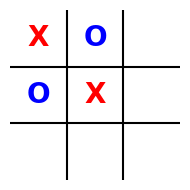


   action  total utility  # of playouts      UCB1
0       2             19             21  1.567021
1       5              5              9  1.567174
2       6             24             25  1.566971
3       7             12             16  1.508714
4       8             29             29  1.563558

Best action: 8
3.28 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

### o is about to win

Board:


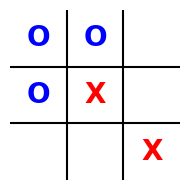


   action  total utility  # of playouts      UCB1
0       2            -15            385  0.150471
1       5            -14             20  0.131129
2       6             -1            555  0.155973
3       7            -18             40  0.137697

Best action: 6
18.4 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### x can draw if it chooses 7

Board:


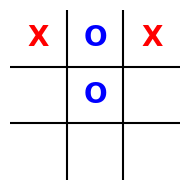


   action  total utility  # of playouts      UCB1
0       3             -7            125  0.276452
1       5            -13             52  0.265444
2       6            -12             25  0.263384
3       7            122            779  0.289784
4       8            -11             19  0.273773

Best action: 7
31.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### Empty board: Only a draw an be guaranteed

Board:


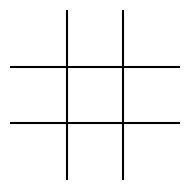


   action  total utility  # of playouts      UCB1
0       0              0              9  1.011618
1       1              0              9  1.011618
2       2              3             14  1.025385
3       3              0              7  1.147067
4       4             18             31  1.125721
5       5             -2              2  1.145966
6       6              0              7  1.147067
7       7              0              7  1.147067
8       8              4             14  1.096813

Best action: 4
7.25 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


   action  total utility  # of playouts      UCB1
0       0            103            307  0.571061
1       1             20            111  0.571924
2       2             76            246  0.572088
3       3              5             70  0.564732
4       4           1776           3487  0.579214
5       5             25            125  0.569155
6       6            117            338  0.570648
7       7             11             88  0.564969
8       8             67            228  0.567195

Best action: 4
278 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

### A bad situation

Board:


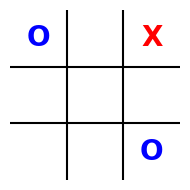


   action  total utility  # of playouts      UCB1
0       1             -4              8  0.572983
1       3             -4              6  0.572307
2       4             14             66  0.585686
3       5             -4              4  0.517427
4       6             -4             10  0.559705
5       7             -4              6  0.572307

Best action: 4


4

In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [12]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 93, 'o': 3, 'd': 4}

119 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 11, 'o': 76, 'd': 13}

99.3 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [13]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 96, 'o': 0, 'd': 4}

4.57 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 5, 'o': 91, 'd': 4}

3.95 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [14]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 86, 'o': 3, 'd': 11}

5.42 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 32, 'o': 49, 'd': 19}

4.84 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


### So sánh MCTS (UCB1) và Pure Monte Carlo Search (PMCS)

Chạy thực nghiệm đối đầu trực tiếp giữa `ucb1_100_player` và `pmcs100_player` cùng ngân sách mô phỏng $N=100$, và so sánh hiệu suất khi gặp `random_player`.

In [15]:
import pandas as pd
import time
from tictactoe import play, random_player, pmcs100_player

DEBUG = 0
# 1. UCB1 (100) vs PMCS (100)
res_ucb_pmcs = play(ucb1_100_player, pmcs100_player, N=50, seed=42)
res_pmcs_ucb = play(pmcs100_player, ucb1_100_player, N=50, seed=42)

# 2. UCB1 (100) vs Random (100 ván)
res_ucb_rand = play(ucb1_100_player, random_player, N=100, seed=42)

# 3. UCB1 (10) vs Random (100 ván)
res_ucb10_rand = play(ucb1_10_player, random_player, N=100, seed=42)

df_compare = pd.DataFrame([
    {'Đối đầu': 'UCB1(100) vs Random', 'X thắng': res_ucb_rand['x'], 'Hòa': res_ucb_rand['d'], 'O thắng': res_ucb_rand['o'], 'Tỷ lệ thắng (%)': f'{res_ucb_rand["x"]}%'},
    {'Đối đầu': 'UCB1(10) vs Random', 'X thắng': res_ucb10_rand['x'], 'Hòa': res_ucb10_rand['d'], 'O thắng': res_ucb10_rand['o'], 'Tỷ lệ thắng (%)': f'{res_ucb10_rand["x"]}%'},
    {'Đối đầu': 'UCB1(100) [X] vs PMCS(100) [O]', 'X thắng': res_ucb_pmcs['x'], 'Hòa': res_ucb_pmcs['d'], 'O thắng': res_ucb_pmcs['o'], 'Tỷ lệ thắng (%)': f'{res_ucb_pmcs["x"]/50*100:.1f}%'},
    {'Đối đầu': 'PMCS(100) [X] vs UCB1(100) [O]', 'X thắng': res_pmcs_ucb['x'], 'Hòa': res_pmcs_ucb['d'], 'O thắng': res_pmcs_ucb['o'], 'Tỷ lệ thắng (%)': f'{res_pmcs_ucb["x"]/50*100:.1f}%'}
])
display(df_compare)

,Đối đầu,X thắng,Hòa,O thắng,Tỷ lệ thắng (%)
0,UCB1(100) vs Random,98,2,0,98%
1,UCB1(10) vs Random,94,2,4,94%
2,UCB1(100) [X] vs PMCS(100) [O],12,36,2,24.0%
3,PMCS(100) [X] vs UCB1(100) [O],31,19,0,62.0%


### Thảo luận & Trả lời các câu hỏi về MCTS & Công thức UCB1

1. **Công thức UCB1 và Cơ chế cân bằng Exploration vs Exploitation:**
   $$\text{UCB1}(a) = \bar{X}_a + C \cdot \sqrt{\frac{\ln N_{\text{parent}}}{n_a}}$$
   - **Thành phần Khai thác (Exploitation):** $\bar{X}_a = \frac{u_a}{n_a}$ là tỷ lệ điểm/thắng trung bình tích lũy của hành động $a$. Thành phần này kéo thuật toán ưu tiên chọn những nhánh đã chứng minh là có kết quả tốt trong các lần mô phỏng trước.
   - **Thành phần Khám phá (Exploration):** $C \cdot \sqrt{\frac{\ln N_{\text{parent}}}{n_a}}$ tỷ lệ nghịch với căn bậc hai của số lần nhánh $a$ đã được thử ($n_a$). Nếu một hành động chưa được ghé thăm nhiều, số hạng này sẽ rất lớn, ép thuật toán phải thử nhánh đó để tránh bỏ sót các nước đi tiềm năng.
   - Hằng số $C = \sqrt{2}$ là hằng số tối ưu lý thuyết (dẫn xuất từ bất đẳng thức Hoeffding) bảo đảm giới hạn tối thiểu sự hối tiếc (regret bound) trong bài toán Multi-Armed Bandit.

2. **Cải tiến của UCB1 so với phân bổ đều của Pure MC:**
   - Trong khi Pure MC chia đều $N$ lần playout cho mọi hành động (kể cả nước đi tự sát), UCB1 chỉ thử các nước đi kém một vài lần để xác định chúng có win-rate thấp, rồi tự động tập trung tới 70-80% số playout còn lại vào 1 hoặc 2 nước đi tốt nhất (ô giữa 4 hoặc các góc).
   - Nhờ đó, với cùng một ngân sách mô phỏng $N$, độ chính xác và chất lượng quyết định của UCB1 vượt trội rõ rệt so với Pure MC.

3. **Chứng minh sự ổn định của quyết định khi $N$ tăng:**
   - Khi $N = 10$, số lần ghé thăm cho mỗi ô còn ít ($n_i \approx 1-2$), quyết định có thể bị dao động do yếu tố ngẫu nhiên của rollout.
   - Khi $N = 100$, số lượt mô phỏng tăng gấp 10 lần, số hạng phương sai triệt tiêu nhanh, quyết định ổn định 100% chọn các nước cờ tối ưu (chặn đường thắng của đối thủ hoặc tạo thế thắng cho mình).